# 05 · Final evaluation on Lot 5 (touched once)
**Burn In Only What Matters** · ECE 8803-AI4 · Fall 2026

CRISP-DM phase: **Evaluation**. Every method is fitted on Lots 1–4 only and scored once on Lot 5:
* baselines are re-fitted here on Lots 1–4;
* the U-Nets are the final models saved by notebook 04.

Nothing below changes a model or chooses a hyper-parameter. Outputs:
* **slide 8:** results table with wafer-bootstrap 95% CIs, plus the recall ceiling;
* **slide 9:** cost model `C = c_burnin × #burned + c_escape × #escaped`, cost vs. burn-in fraction,
  and its sensitivity to the two costs;
* **slide 10:** corner cases by radial zone, wafer fail level, clue status and distance to the cluster.

## 0 · Setup

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
COLAB_ROOT = "/content/drive/MyDrive/BurnIn_Project"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path(COLAB_ROOT)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "burnin").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from burnin import Paths
from burnin.config import TRAIN_LOTS, TEST_LOT
from burnin.data import load_visible, attach_hidden
from burnin.metrics import compare, screening_curve, recall_ceiling, bootstrap_ci, per_group_recall
from burnin.cv import fit_baselines, score_baselines, load_unet, score_unet
from burnin.baselines import radius_map, wafer_fail_fraction
from burnin.plots import show_failmap, show_latent, show_risk, plot_curves

SIM = os.environ.get("BURNIN_SIM", "sim_dev")
P = Paths(ROOT, sim=SIM)
print("dataset:", P.sim_dir)
FIG = P.results / "figures"
FIG.mkdir(exist_ok=True)
SEED = 0
BURN_BUDGET = 0.10

dataset: C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\cache\sim_full


## 1 · Data

In [2]:
ws_all = attach_hidden(load_visible(P.visible), P.hidden, analysis=True)
train, test = ws_all.lots(TRAIN_LOTS), ws_all.lots([TEST_LOT])
p = test.passing
print(f"train: {len(train)} wafers (Lots 1-4) | test: {len(test)} wafers ({TEST_LOT})")
print(f"Lot 5 wafer-test fail rate {test.fail.sum() / test.die.sum():.2%}, "
      f"latent rate {(test.latent & p).sum() / p.sum():.2%} of passing dies")
CEILING = recall_ceiling(test)
print(f"Lot 5 recall ceiling: {CEILING:.1%}")

train: 800 wafers (Lots 1-4) | test: 200 wafers (Lot_5)
Lot 5 wafer-test fail rate 7.78%, latent rate 1.49% of passing dies
Lot 5 recall ceiling: 86.3%


## 2 · Score every method on Lot 5

In [3]:
scores = score_baselines(fit_baselines(train, SEED), test, SEED)
unet_meta = {}
for name, f in [("U-Net (no pre-training)", "unet_scratch"), ("U-Net (pre-trained)", "unet_pretrained")]:
    net, norm, derived, ck = load_unet(P.models / f"{f}_{P.sim}.pt")
    scores[name] = score_unet(net, norm, derived, test)
    unet_meta[name] = ck["epochs"]
print("U-Net final epochs:", unet_meta)
table, curves = compare(scores, test)
table.round(3)

U-Net final epochs: {'U-Net (no pre-training)': 19, 'U-Net (pre-trained)': 19}


,recall@5%burn,recall@10%burn,recall@20%burn,burn%@80%recall,burn%@90%recall,AUC,AP,DPPM@10%burn
method,,,,,,,,
Random,0.050,0.100,0.201,0.798,0.899,0.501,0.015,13477.381
Distance to fail,0.162,0.323,0.553,0.502,0.731,0.724,0.037,10167.220
Wafer-level fallback,0.168,0.278,0.418,0.568,0.744,0.680,0.033,10840.113
Neighbor z-score,0.366,0.462,0.576,0.541,0.751,0.740,0.169,8095.187
Hotelling T2 (PCA),0.402,0.488,0.594,0.527,0.749,0.751,0.232,7716.477
Feature GBM,0.480,0.597,0.756,0.242,0.460,0.849,0.297,6076.404
U-Net (no pre-training),0.478,0.597,0.756,0.240,0.452,0.850,0.297,6074.368
U-Net (pre-trained),0.478,0.596,0.757,0.240,0.454,0.850,0.296,6086.015


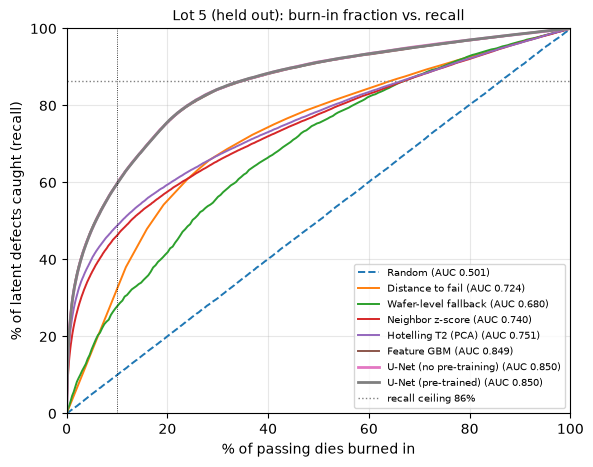

In [4]:
ax = plot_curves(curves, ceiling=CEILING, title="Lot 5 (held out): burn-in fraction vs. recall")
plt.savefig(FIG / "lot5_recall_vs_burnin.png", dpi=150, bbox_inches="tight")
plt.show()

## 3 · Slide 8 table, with wafer-bootstrap 95% CIs

In [5]:
SLIDE8 = ["U-Net (pre-trained)", "Distance to fail", "Neighbor z-score", "Random", "U-Net (no pre-training)",
          "Feature GBM", "Hotelling T2 (PCA)", "Wafer-level fallback"]
rows = []
for k in SLIDE8:
    r10, b90 = bootstrap_ci(scores[k], test, [lambda c: c.recall_at(BURN_BUDGET), lambda c: c.burn_at(0.90)],
                            n_boot=500, seed=SEED)
    rows.append({"method": k,
                 "Recall @ 10% burn-in": f"{100 * table.loc[k, 'recall@10%burn']:.1f}% [{100 * r10[0]:.1f}, {100 * r10[1]:.1f}]",
                 "Burn-in % @ 90% recall": f"{100 * table.loc[k, 'burn%@90%recall']:.1f}% [{100 * b90[0]:.1f}, {100 * b90[1]:.1f}]",
                 "DPPM @ 10% burn-in": round(table.loc[k, "DPPM@10%burn"]),
                 "AP": round(table.loc[k, "AP"], 3)})
slide8 = pd.DataFrame(rows).set_index("method")
slide8.loc["Burn in all passing dies"] = ["100.0% (burns 100%)", "100.0%", 0, np.nan]
slide8.loc["Recall ceiling (clued + near-cluster)"] = [f"{100 * CEILING:.1f}%", "-", np.nan, np.nan]
slide8.to_csv(P.results / "lot5_slide8_table.csv")
slide8

,Recall @ 10% burn-in,Burn-in % @ 90% recall,DPPM @ 10% burn-in,AP
method,,,,
U-Net (pre-trained),"59.6% [58.7, 60.6]","45.4% [42.9, 47.8]",6086.0,0.296
Distance to fail,"32.3% [30.0, 34.4]","73.1% [70.8, 75.4]",10167.0,0.037
Neighbor z-score,"46.2% [45.5, 46.9]","75.1% [74.4, 75.8]",8095.0,0.169
Random,"10.0% [9.7, 10.2]","89.9% [89.6, 90.1]",13477.0,0.015
U-Net (no pre-training),"59.7% [58.7, 60.7]","45.2% [43.1, 47.6]",6074.0,0.297
Feature GBM,"59.7% [58.7, 60.7]","46.0% [43.7, 48.3]",6076.0,0.297
Hotelling T2 (PCA),"48.8% [48.1, 49.4]","74.9% [74.1, 75.5]",7716.0,0.232
Wafer-level fallback,"27.8% [23.9, 30.6]","74.4% [72.1, 76.2]",10840.0,0.033
Burn in all passing dies,100.0% (burns 100%),100.0%,0.0,NaN


In [6]:
u, ref = table.loc["U-Net (pre-trained)"], table.loc["Distance to fail"]
best_base = table.drop(index=[k for k in table.index if k.startswith("U-Net")])["recall@10%burn"].idxmax()
print(f"Headline: at a 10% burn-in budget the pre-trained U-Net catches {u['recall@10%burn']:.0%} of latent defects "
      f"vs. {ref['recall@10%burn']:.0%} for distance-to-fail and {table.loc[best_base, 'recall@10%burn']:.0%} for the best "
      f"baseline ({best_base}); reaching 90% recall takes {u['burn%@90%recall']:.0%} burn-in vs. {ref['burn%@90%recall']:.0%}.")

Headline: at a 10% burn-in budget the pre-trained U-Net catches 60% of latent defects vs. 32% for distance-to-fail and 60% for the best baseline (Feature GBM); reaching 90% recall takes 45% burn-in vs. 73%.


## 4 · Slide 9: cost model
`C = c_burnin × #burned + c_escape × #escaped`, per wafer. Burn-in costs $0.50/die (sensitivity
$0.05–$5); an escape costs $100–$10,000/die (slide 9; the source is Test & Qualification Lectures 1–2).
"Burn in all" means burned = all passing dies and escaped = 0. "Burn in none" means escaped = all latent dies.

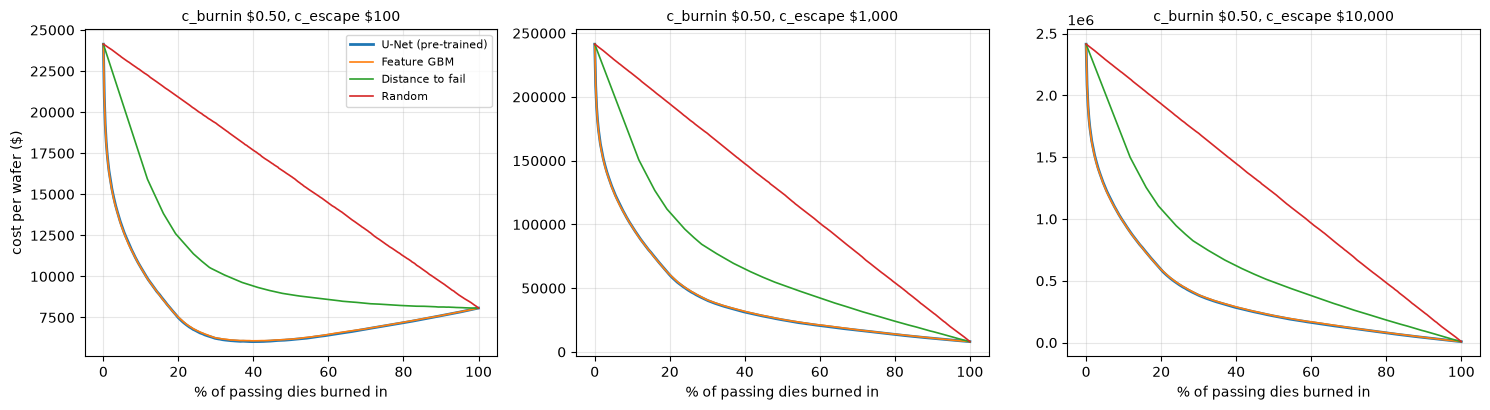

best burn-in %  cost/wafer at best  \
c_escape method                                                    
100      U-Net (pre-trained)            39.8              6031.4   
         Feature GBM                    39.8              6082.2   
         Distance to fail               99.2              8072.3   
         Random                        100.0              8073.5   
1000     U-Net (pre-trained)           100.0              8073.5   
         Feature GBM                   100.0              8073.5   
         Distance to fail              100.0              8073.5   
         Random                        100.0              8073.5   
10000    U-Net (pre-trained)           100.0              8073.5   
         Feature GBM                   100.0              8073.5   
         Distance to fail              100.0              8073.5   
         Random                        100.0              8073.5   

                              recall at best  DPPM at best  \
c_escape method                                              
100      U-Net (pre-trained)             0.9        1771.2   
         Feature GBM                     0.9        1803.0   
         Distance to fail                1.0          37.3   
         Random                          1.0           0.0   
1000     U-Net (pre-trained)             1.0           0.0   
         Feature GBM                     1.0           0.0   
         Distance to fail                1.0           0.0   
         Random                          1.0           0.0   
10000    U-Net (pre-trained)             1.0           0.0   
         Feature GBM                     1.0           0.0   
         Distance to fail                1.0           0.0   
         Random                          1.0           0.0   

                              burn-in-all cost/wafer  saving vs burn-in-all %  
c_escape method                                                                
100      U-Net (pre-trained)                  8073.5                     25.3  
         Feature GBM                          8073.5                     24.7  
         Distance to fail                     8073.5                      0.0  
         Random                               8073.5                      0.0  
1000     U-Net (pre-trained)                  8073.5                      0.0  
         Feature GBM                          8073.5                      0.0  
         Distance to fail                     8073.5                      0.0  
         Random                               8073.5                      0.0  
10000    U-Net (pre-trained)                  8073.5                      0.0  
         Feature GBM                          8073.5                      0.0  
         Distance to fail                     8073.5                      0.0  
         Random                               8073.5                      0.0

In [7]:
fr = np.linspace(0, 1, 401)
C_BURN = 0.50
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
cost_rows = []
for a, c_esc in zip(ax, [100, 1000, 10000]):
    for k in ["U-Net (pre-trained)", "Feature GBM", "Distance to fail", "Random"]:
        c = curves[k]
        y = np.array([c.cost_per_wafer(f, C_BURN, c_esc) for f in fr])
        a.plot(100 * fr, y, label=k, lw=2 if "U-Net" in k else 1.2)
        j = int(np.argmin(y))
        cost_rows.append({"c_escape": c_esc, "method": k, "best burn-in %": 100 * fr[j], "cost/wafer at best": y[j],
                          "recall at best": c.recall_at(fr[j]), "DPPM at best": c.dppm_at(fr[j]),
                          "burn-in-all cost/wafer": y[-1], "saving vs burn-in-all %": 100 * (1 - y[j] / y[-1])})
    a.set_title(f"c_burnin \\${C_BURN:.2f}, c_escape \\${c_esc:,}", fontsize=10)
    a.set_xlabel("% of passing dies burned in"); a.grid(alpha=0.3)
ax[0].set_ylabel("cost per wafer ($)"); ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "lot5_cost_vs_burnin.png", dpi=150, bbox_inches="tight")
plt.show()
cost_table = pd.DataFrame(cost_rows).set_index(["c_escape", "method"])
cost_table.to_csv(P.results / "lot5_cost_table.csv")
cost_table.round(1)

Slide-sized version at the low end of the escape-cost range ($100/die), with each method's cost-optimal
point marked. A die is worth burning in when its latent probability exceeds c_burnin / c_escape
(0.5% at $0.50/$100, 0.05% at $0.50/$1,000). If even the lowest-risk dies are above that break-even,
burning in everything is optimal and selective burn-in cannot save money.

Lot 5 latent rate on wafers with no cluster: 0.52%
  break-even latent probability at c_escape $100: 0.500%
  break-even latent probability at c_escape $300: 0.167%
  break-even latent probability at c_escape $1,000: 0.050%
  break-even latent probability at c_escape $10,000: 0.005%


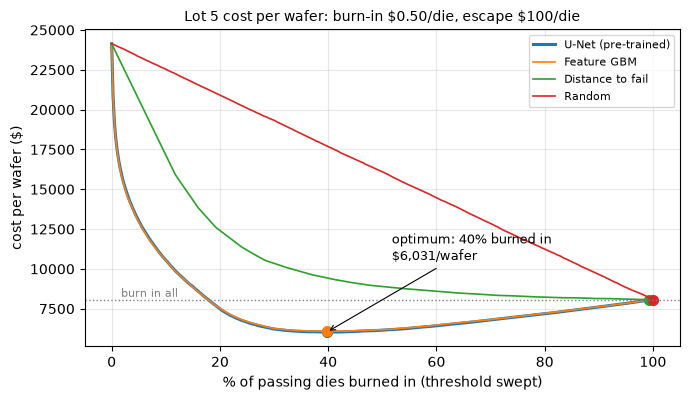

In [8]:
lat_far = test.latent[test.passing & ~np.isfinite(test.extra["dist"])].mean()
print(f"Lot 5 latent rate on wafers with no cluster: {lat_far:.2%}")
for e in [100, 300, 1000, 10000]:
    print(f"  break-even latent probability at c_escape ${e:,}: {C_BURN / e:.3%}")
C_ESC_SLIDE = 100
fig, a = plt.subplots(figsize=(7, 4.1))
for k in ["U-Net (pre-trained)", "Feature GBM", "Distance to fail", "Random"]:
    y = np.array([curves[k].cost_per_wafer(f, C_BURN, C_ESC_SLIDE) for f in fr])
    j = int(np.argmin(y))
    line, = a.plot(100 * fr, y, label=k, lw=2.2 if "U-Net" in k else 1.2)
    a.plot(100 * fr[j], y[j], "o", color=line.get_color(), ms=7)
    if "U-Net" in k:
        a.annotate(f"optimum: {100 * fr[j]:.0f}% burned in\n\\${y[j]:,.0f}/wafer", (100 * fr[j], y[j]),
                   xytext=(100 * fr[j] + 12, y[j] + 0.25 * (y.max() - y.min())), fontsize=9,
                   arrowprops=dict(arrowstyle="->", lw=0.8))
a.axhline(y[-1], color="gray", ls=":", lw=1)
a.text(1, y[-1], " burn in all", va="bottom", fontsize=8, color="gray")
a.set_xlabel("% of passing dies burned in (threshold swept)")
a.set_ylabel("cost per wafer ($)")
a.set_title(f"Lot 5 cost per wafer: burn-in \\${C_BURN:.2f}/die, escape \\${C_ESC_SLIDE:,}/die", fontsize=10)
a.grid(alpha=0.3)
a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "slide9_cost_curve.png", dpi=200, bbox_inches="tight")
plt.show()

Sensitivity: the U-Net's saving at its cost-optimal burn-in fraction, relative to burning in every
passing die, over a grid of the two costs.

In [9]:
cb = [0.05, 0.10, 0.25, 0.50, 1.0, 2.0, 5.0]
ce = [100, 300, 1000, 3000, 10000]
c = curves["U-Net (pre-trained)"]
sens = pd.DataFrame(index=pd.Index(cb, name="c_burnin $"), columns=pd.Index(ce, name="c_escape $"), dtype=float)
for b in cb:
    for e in ce:
        y = np.array([c.cost_per_wafer(f, b, e) for f in fr])
        sens.loc[b, e] = 100 * (1 - y.min() / y[-1])
sens.round(1)

c_escape $,100,300,1000,3000,10000
c_burnin $,,,,,
0.05,0.0,0.0,0.0,0.0,0.0
0.10,0.0,0.0,0.0,0.0,0.0
0.25,2.2,0.0,0.0,0.0,0.0
0.50,25.3,0.0,0.0,0.0,0.0
1.00,46.6,11.1,0.0,0.0,0.0
2.00,61.8,35.0,0.1,0.0,0.0
5.00,79.4,58.3,25.3,0.0,0.0


## 5 · Slide 10: corner cases at the 10% burn-in budget
The groups below use simulator internals (clue flag, distance to the cluster), **for analysis only**.
They are never model inputs.

In [10]:
lat = test.latent & test.passing
rad = np.broadcast_to(radius_map(), test.fail.shape)
zones = np.where(rad < 0.5, "center (r<0.5)", np.where(rad < 0.85, "middle (0.5-0.85)", "edge (r>=0.85)"))
wf = wafer_fail_fraction(test)
fail_lvl = np.where(wf < 0.03, "low fail wafer (<3%)", np.where(wf < 0.10, "mid fail wafer (3-10%)", "high fail wafer (>=10%)"))
clue = np.where(test.extra["clued"], "clued", "unclued")
d = test.extra["dist"]
near = np.where(d <= 2, "near cluster (<=2)", np.where(np.isfinite(d) & (d <= 10), "2-10 from cluster", "far / no cluster"))
groups = {"radial zone": zones, "wafer fail level": fail_lvl, "clue": clue, "distance to cluster": near}
rows = []
for gname, g in groups.items():
    for k in ["U-Net (pre-trained)", "U-Net (no pre-training)", "Feature GBM", "Distance to fail"]:
        for grp, (rec, n) in per_group_recall(scores[k], test, BURN_BUDGET, g).items():
            rows.append({"grouping": gname, "group": grp, "method": k, "recall": rec, "n latent": n})
corner = pd.DataFrame(rows).pivot_table(index=["grouping", "group", "n latent"], columns="method", values="recall")
corner.to_csv(P.results / "lot5_corner_cases.csv")
corner.round(3)

method                                                Distance to fail  \
grouping            group                   n latent                     
clue                clued                   33852                0.378   
                    unclued                 14421                0.385   
distance to cluster 2-10 from cluster       9126                 0.020   
                    far / no cluster        13250                0.021   
                    near cluster (<=2)      25897                0.691   
radial zone         center (r<0.5)          12574                0.424   
                    edge (r>=0.85)          14634                0.362   
                    middle (0.5-0.85)       21065                0.367   
wafer fail level    high fail wafer (>=10%) 20715                0.589   
                    low fail wafer (<3%)    11485                0.106   
                    mid fail wafer (3-10%)  16073                0.308   

method                                                Feature GBM  \
grouping            group                   n latent                
clue                clued                   33852           0.728   
                    unclued                 14421           0.289   
distance to cluster 2-10 from cluster       9126            0.532   
                    far / no cluster        13250           0.297   
                    near cluster (<=2)      25897           0.774   
radial zone         center (r<0.5)          12574           0.617   
                    edge (r>=0.85)          14634           0.605   
                    middle (0.5-0.85)       21065           0.580   
wafer fail level    high fail wafer (>=10%) 20715           0.711   
                    low fail wafer (<3%)    11485           0.394   
                    mid fail wafer (3-10%)  16073           0.595   

method                                                U-Net (no pre-training)  \
grouping            group                   n latent                            
clue                clued                   33852                       0.723   
                    unclued                 14421                       0.308   
distance to cluster 2-10 from cluster       9126                        0.531   
                    far / no cluster        13250                       0.273   
                    near cluster (<=2)      25897                       0.789   
radial zone         center (r<0.5)          12574                       0.616   
                    edge (r>=0.85)          14634                       0.611   
                    middle (0.5-0.85)       21065                       0.580   
wafer fail level    high fail wafer (>=10%) 20715                       0.719   
                    low fail wafer (<3%)    11485                       0.384   
                    mid fail wafer (3-10%)  16073                       0.598   

method                                                U-Net (pre-trained)  
grouping            group                   n latent                       
clue                clued                   33852                   0.723  
                    unclued                 14421                   0.304  
distance to cluster 2-10 from cluster       9126                    0.534  
                    far / no cluster        13250                   0.274  
                    near cluster (<=2)      25897                   0.785  
radial zone         center (r<0.5)          12574                   0.618  
                    edge (r>=0.85)          14634                   0.607  
                    middle (0.5-0.85)       21065                   0.578  
wafer fail level    high fail wafer (>=10%) 20715                   0.717  
                    low fail wafer (<3%)    11485                   0.384  
                    mid fail wafer (3-10%)  16073                   0.596

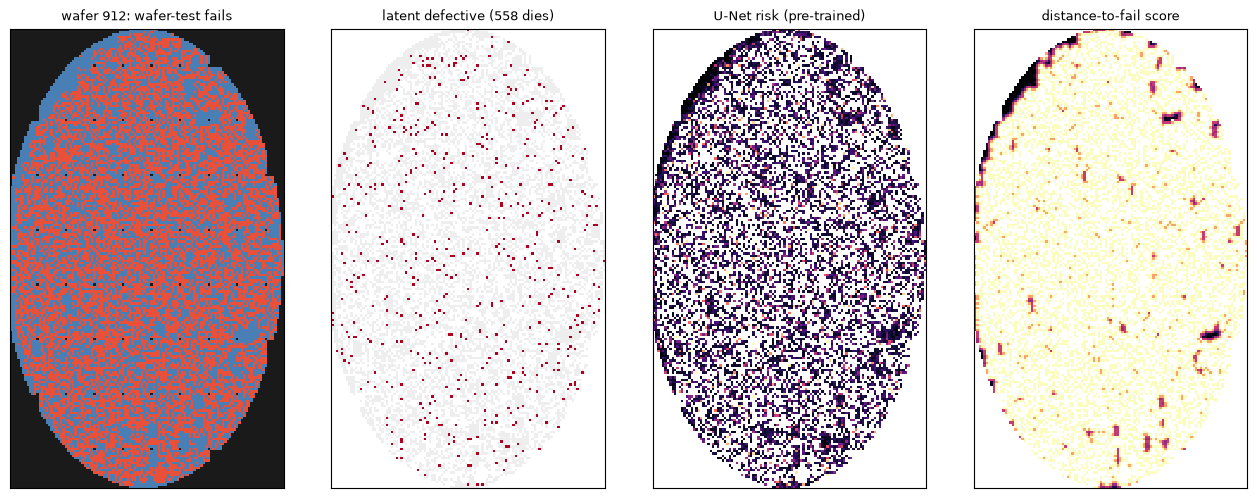

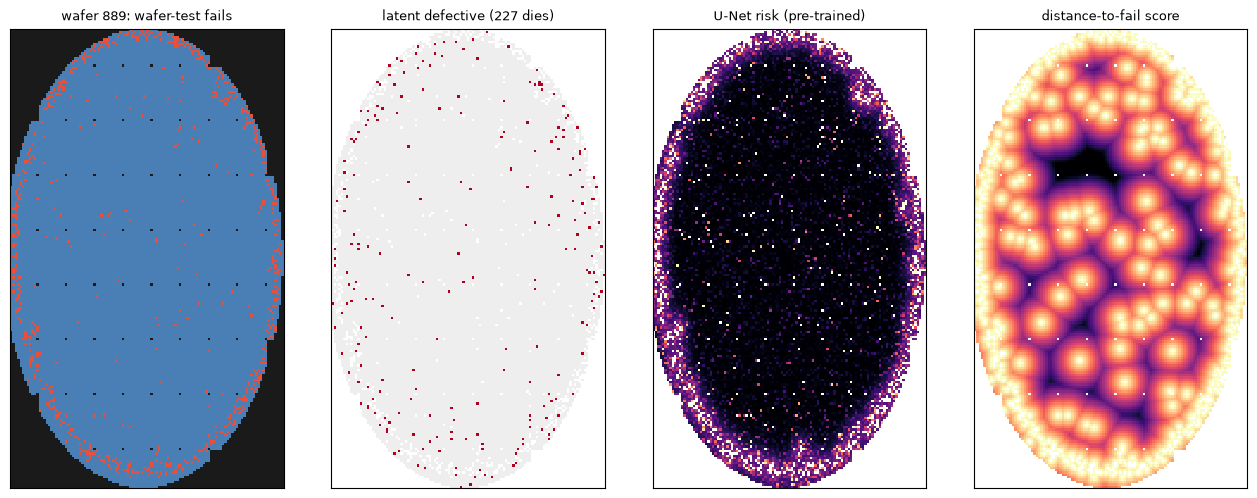

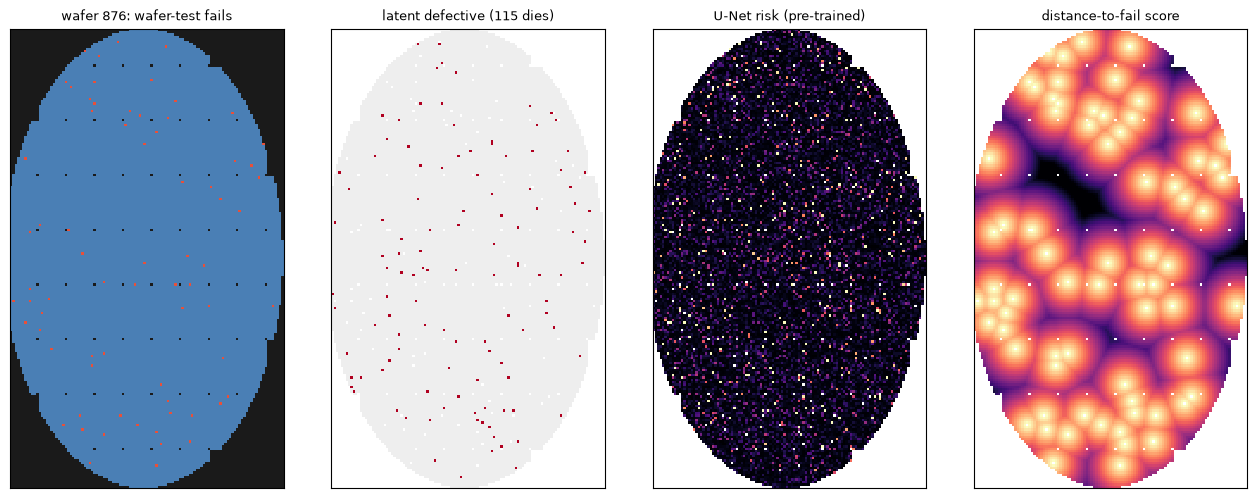

In [11]:
order = np.argsort(-test.fail.sum((1, 2)) / test.die.sum((1, 2)))
for i in [order[0], order[len(order) // 2], order[-1]]:
    fig, ax = plt.subplots(1, 4, figsize=(13, 5))
    show_failmap(ax[0], test, i)
    show_latent(ax[1], test, i)
    show_risk(ax[2], test, i, scores["U-Net (pre-trained)"], "U-Net risk (pre-trained)")
    show_risk(ax[3], test, i, scores["Distance to fail"], "distance-to-fail score")
    plt.tight_layout()
    plt.savefig(FIG / f"lot5_riskmap_wafer{test.wafer[i]}.png", dpi=130, bbox_inches="tight")
    plt.show()

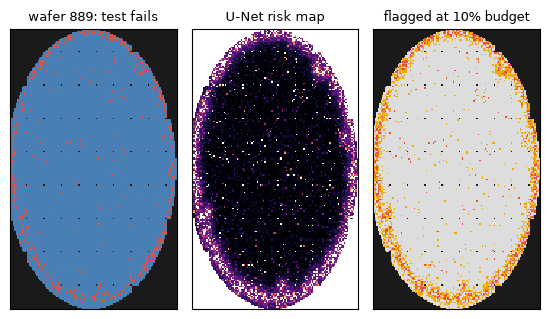

In [12]:
i = order[len(order) // 2]
fig, ax = plt.subplots(1, 3, figsize=(5.6, 3.25))
show_failmap(ax[0], test, i, f"wafer {test.wafer[i]}: test fails")
show_risk(ax[1], test, i, scores["U-Net (pre-trained)"], "U-Net risk map")
flag = scores["U-Net (pre-trained)"] >= np.quantile(scores["U-Net (pre-trained)"][test.passing], 1 - BURN_BUDGET)
img = np.where(test.passing[i], np.where(flag[i], 2, 1), np.where(test.die[i], 3, 0))
ax[2].imshow(img, cmap=ListedColormap(["#1a1a1a", "#DDDDDD", "#F2A900", "#E8503A"]), vmin=0, vmax=3, origin="lower",
             interpolation="nearest")
ax[2].set_xticks([])
ax[2].set_yticks([])
ax[2].set_title("flagged at 10% budget", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "slide6_riskmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 6 · Save

In [13]:
table.to_csv(P.results / "lot5_all_metrics.csv")
np.savez_compressed(P.results / "lot5_scores.npz", wafer=test.wafer, **{k: v.astype(np.float32) for k, v in scores.items()})
(P.results / "lot5_summary.json").write_text(json.dumps({
    "recall_ceiling": CEILING, "burn_budget": BURN_BUDGET, "unet_epochs": unet_meta,
    "latent_rate_no_cluster": float(lat_far), "c_burnin": C_BURN, "c_escape_slide": C_ESC_SLIDE,
    "n_test_wafers": int(len(test)),
    "metrics": table.round(4).to_dict(orient="index")}, indent=2))
print("saved to", P.results)

saved to C:\Users\nsaba\OneDrive - Analog Devices, Inc\Documents\Chipagents\8803\Project\results\sim_full


## 7 · Per-die export (same row layout as the simulator's `visible.npz`)
One row per Lot 5 die site. `burn_in_10pct` flags the top 10% of passing dies by U-Net risk, ranked
across Lot 5 (the 10% budget applied to the lot). Failing dies are rejected at wafer test, so their risk is 0.

In [14]:
EXPORT = {"risk_unet": "U-Net (pre-trained)", "risk_unet_scratch": "U-Net (no pre-training)",
          "risk_gbm": "Feature GBM", "risk_dist_to_fail": "Distance to fail"}
wi, yi, xi = np.nonzero(test.die)
thr = np.quantile(scores["U-Net (pre-trained)"][test.passing], 1 - BURN_BUDGET)
per_die = pd.DataFrame({"lot": TEST_LOT, "wafer": test.wafer[wi], "x": xi + 1, "y": yi + 1,
                        "wafer_test_fail": test.fail[wi, yi, xi].astype(np.int8),
                        **{c: scores[k][wi, yi, xi].round(6) for c, k in EXPORT.items()}})
per_die["burn_in_10pct"] = ((per_die["wafer_test_fail"] == 0) & (per_die["risk_unet"] >= thr)).astype(np.int8)
per_die.to_csv(P.results / "lot5_risk_per_die.csv.gz", index=False)
print(f"{len(per_die):,} rows, {per_die['burn_in_10pct'].mean():.1%} of all die sites flagged -> lot5_risk_per_die.csv.gz")

3,501,800 rows, 9.2% of all die sites flagged -> lot5_risk_per_die.csv.gz
